## Objective
The objective of this project is to build an XGBoost Regressor for predicting medical insurance charges using customer characteristics such as age, sex, BMI, number of children, smoking status, and region. The dataset will be examined, cleaned, and explored before developing baseline and tuned regression models. Model performance will be evaluated using MSE, MAE, RMSE, MAPE, and R² score to understand the prediction results from different perspectives. An appropriate scoring metric will be selected for hyperparameter tuning based on the problem statement, prediction objective, and characteristics of the target variable. Training and testing performance will also be compared to identify possible overfitting. The final model will be selected based on its overall predictive performance and its ability to generalise well to unseen data.

## **Task 1**
- *Import the libraries required for data preparation, modelling, evaluation, and visualisation*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

from xgboost import XGBRegressor
RANDOM_STATE = 42
pd.options.display.float_format = '{:,.3f}'.format
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

# Data Preparation

## **Task 2**

- *Load the dataset and display the first few records*
- *Check the dataset shape, data types, and column names*
- *Check for missing values and duplicate records*
- *Remove duplicate records from the dataset*

In [2]:
ins = pd.read_csv('../data/insurance.csv')
display(ins.head())
print('Shape:', ins.shape)
print('\nData types:\n', ins.dtypes.to_string())
print('\nMissing values:', int(ins.isna().sum().sum()))
dups = ins[ins.duplicated(keep=False)]
print('Duplicate rows:', ins.duplicated().sum()); display(dups)
ins = ins.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', ins.shape)
display(ins['charges'].describe().round(0).to_frame().T)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,"16,884.924"
1,18,male,33.770,1,no,southeast,"1,725.552"
2,28,male,33.000,3,no,southeast,"4,449.462"
3,33,male,22.705,0,no,northwest,"21,984.471"
4,32,male,28.880,0,no,northwest,"3,866.855"


Shape: (1338, 7)

Data types:
 age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64

Missing values: 0
Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.590,0,no,northwest,"1,639.563"
581,19,male,30.590,0,no,northwest,"1,639.563"


Shape after removing duplicates: (1337, 7)


,count,mean,std,min,25%,50%,75%,max
charges,"1,337.000","13,279.000","12,110.000","1,122.000","4,746.000","9,386.000","16,658.000","63,770.000"


**Observation:** 1,338 policyholders, no missing values, and one exact duplicate, which was removed (1,337 rows remain). Charges are right-skewed: median USD 9,386, mean USD 13,279, maximum USD 63,770.

## **Task 3**
- *Compare the average insurance charges for smokers and non-smokers using a bar chart*

,mean,median,count
smoker,,,
no,"8,441.000","7,346.000",1063
yes,"32,050.000","34,456.000",274


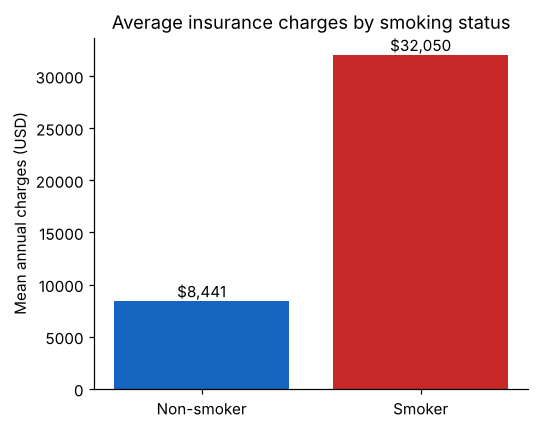

In [3]:
smoker_stats = ins.groupby('smoker')['charges'].agg(['mean', 'median', 'count']).round(0)
display(smoker_stats)
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Non-smoker', 'Smoker'], smoker_stats['mean'], color=['#1565C0', '#C62828'])
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in smoker_stats['mean']])
ax.set_ylabel('Mean annual charges (USD)'); ax.set_title('Average insurance charges by smoking status')
plt.tight_layout(); plt.savefig(FIG_DIR / 'charges_by_smoker.png', bbox_inches='tight'); plt.show()

**Observation:** Smokers are charged 3.8x more on average (USD 32,050 vs 8,441). With smokers making up 20% of policyholders, smoking status will dominate any model. The train-test split is stratified on it so both sets keep the same smoker share.

## **Task 4**
- *Separate the predictor variables and the target variable*

In [4]:
X = ins.drop(columns='charges')
y = ins['charges']
CAT_COLS = ['sex', 'smoker', 'region']
NUM_COLS = ['age', 'bmi', 'children']

## **Task 5**
- *Split the feature and target datasets into training and testing sets*

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=X['smoker'])
print(f'Train: {X_train.shape} | Test: {X_test.shape} | smoker share train/test: '
      f'{(X_train.smoker == "yes").mean():.3f} / {(X_test.smoker == "yes").mean():.3f}')

Train: (1069, 6) | Test: (268, 6) | smoker share train/test: 0.205 / 0.205


## **Task 6**
- *Encode the categorical features by fitting the encoder on the training data and applying the same transformation to the testing data*

In [6]:
encoder = ColumnTransformer([('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), CAT_COLS)],
                            remainder='passthrough', verbose_feature_names_out=False)
X_train_enc = pd.DataFrame(encoder.fit_transform(X_train), columns=encoder.get_feature_names_out(), index=X_train.index)
X_test_enc = pd.DataFrame(encoder.transform(X_test), columns=encoder.get_feature_names_out(), index=X_test.index)
display(X_train_enc.head())

,sex_male,smoker_yes,region_northeast,region_northwest,region_southeast,region_southwest,age,bmi,children
367,0.000,0.000,0.000,1.000,0.000,0.000,42.000,24.985,2.000
418,1.000,0.000,0.000,0.000,1.000,0.000,64.000,39.160,1.000
938,1.000,0.000,0.000,0.000,1.000,0.000,53.000,29.480,0.000
533,1.000,0.000,0.000,0.000,1.000,0.000,37.000,36.190,0.000
354,0.000,0.000,0.000,0.000,1.000,0.000,18.000,38.280,0.000


# Model Training

## **Task 7**
- *Build and train a baseline XGBoost Regressor using the training data*
- *Display the parameters used by the baseline XGBoost model*

In [7]:
baseline_xgb = XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1)
baseline_xgb.fit(X_train_enc, y_train)
params = pd.Series(baseline_xgb.get_params())
print(params[params.notna()].to_string())

objective             reg:squarederror
enable_categorical                True
n_jobs                              -1
random_state                        42


## **Task 8**
- *Generate predictions for the training and testing datasets using the baseline model*

In [8]:
base_train_pred = baseline_xgb.predict(X_train_enc)
base_test_pred = baseline_xgb.predict(X_test_enc)

## **Task 9**
- *Plot the actual and predicted medical insurance charges for the training and testing datasets using the baseline XGBoost model*

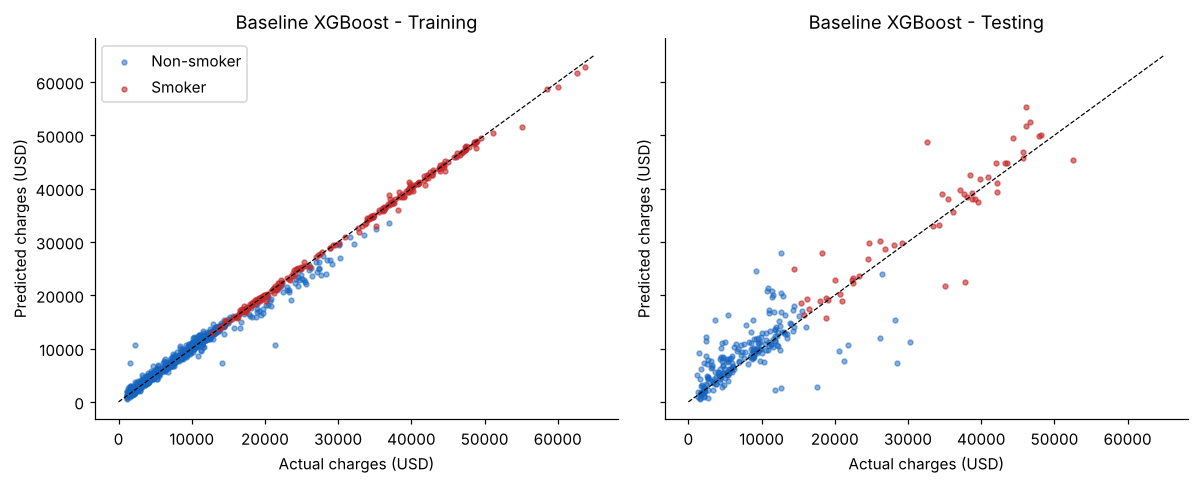

In [9]:
def plot_actual_vs_pred(train_pred, test_pred, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, (split, Xs, yt, yp) in zip(axes, [('Training', X_train, y_train, train_pred), ('Testing', X_test, y_test, test_pred)]):
        smk = (Xs['smoker'] == 'yes').values
        ax.scatter(yt[~smk], yp[~smk], s=10, alpha=0.5, color='#1565C0', label='Non-smoker')
        ax.scatter(yt[smk], yp[smk], s=10, alpha=0.6, color='#C62828', label='Smoker')
        lim = [0, 65000]; ax.plot(lim, lim, '--', color='black', lw=0.8)
        ax.set_title(f'{title} - {split}'); ax.set_xlabel('Actual charges (USD)'); ax.set_ylabel('Predicted charges (USD)')
    axes[0].legend(); plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_actual_vs_pred(base_train_pred, base_test_pred, 'Baseline XGBoost', 'actual_vs_pred_baseline.png')

## **Task 10**
- *Create a line graph to compare the first 50 actual and predicted testing values using the baseline XGBoost model*

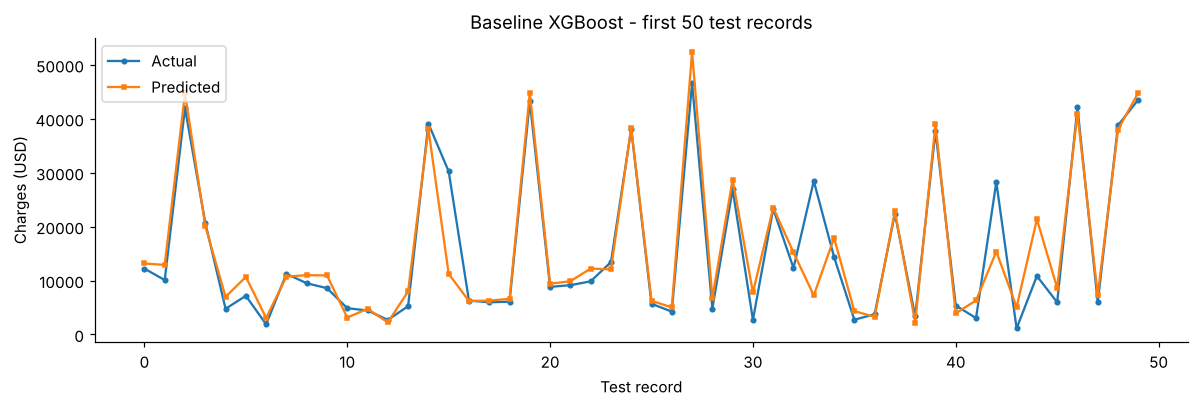

In [10]:
def plot_first_50(test_pred, title, fname):
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.plot(range(50), y_test.values[:50], marker='o', ms=3, label='Actual')
    ax.plot(range(50), test_pred[:50], marker='s', ms=3, label='Predicted')
    ax.set_xlabel('Test record'); ax.set_ylabel('Charges (USD)'); ax.set_title(title); ax.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / fname, bbox_inches='tight'); plt.show()

plot_first_50(base_test_pred, 'Baseline XGBoost - first 50 test records', 'first50_baseline.png')

# Model Interpretation

## **Task 11**
- *Evaluate the baseline model using MSE, MAE, RMSE, MAPE, and R² score for the training and testing datasets*
- *Select an appropriate evaluation metric and calculate the gap between the training and testing scores to check for overfitting*

In [11]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MSE': mse, 'MAE': mean_absolute_error(y_true, y_pred), 'RMSE': np.sqrt(mse),
            'MAPE (%)': 100 * mean_absolute_percentage_error(y_true, y_pred), 'R2': r2_score(y_true, y_pred)}

base_metrics = pd.DataFrame({'Training': regression_metrics(y_train, base_train_pred),
                             'Testing': regression_metrics(y_test, base_test_pred)})
display(base_metrics.round(3))

# Primary metric: MAE (USD). For an insurer, the cost of a pricing error is the dollar amount of the
# under- or over-charge. MAE reads directly in dollars and is not dominated by the handful of very
# large claims the way RMSE is. MAPE is unstable here because charges start near USD 1,100.
PRIMARY = 'MAE'
base_gap = base_metrics.loc[PRIMARY, 'Testing'] - base_metrics.loc[PRIMARY, 'Training']
print(f'Baseline MAE: train = {base_metrics.loc[PRIMARY, "Training"]:,.0f}, test = {base_metrics.loc[PRIMARY, "Testing"]:,.0f}, '
      f'gap (test - train) = {base_gap:,.0f} USD')

,Training,Testing
MSE,"802,027.443","21,695,153.146"
MAE,488.622,"2,845.559"
RMSE,895.560,"4,657.806"
MAPE (%),7.266,39.145
R2,0.995,0.850


Baseline MAE: train = 489, test = 2,846, gap (test - train) = 2,357 USD


**Observation:** The default XGBoost model memorises the training set (train R² 0.995, MAE USD 489) but reaches only R² 0.850 and MAE USD 2,846 on the test set. A train-test gap of USD 2,357 is clear overfitting. The default 100 trees of depth 6 are far too flexible for 1,069 training rows.

**Primary metric: MAE.** It is in dollars, which is how a pricing error costs an insurer, and it is not dominated by a few very large claims the way RMSE is.

## **Task 12**
- *Identify and visualise the five most influential features used by the baseline model*

,Gain-based importance
smoker_yes,0.886
bmi,0.036
age,0.027
children,0.012
region_northwest,0.010


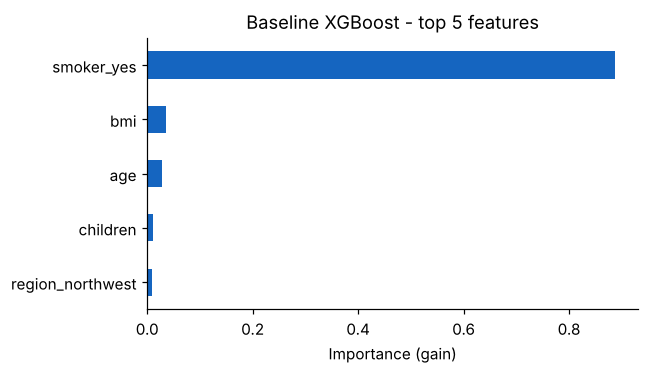

In [12]:
base_imp = pd.Series(baseline_xgb.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
display(base_imp.head(5).round(3).to_frame('Gain-based importance'))
fig, ax = plt.subplots(figsize=(6, 3.5))
base_imp.head(5)[::-1].plot.barh(ax=ax, color='#1565C0')
ax.set_title('Baseline XGBoost - top 5 features'); ax.set_xlabel('Importance (gain)')
plt.tight_layout(); plt.savefig(FIG_DIR / 'feature_importance_baseline.png', bbox_inches='tight'); plt.show()

**Observation:** Smoking status accounts for 89% of the total split gain. BMI (3.6%) and age (2.7%) come next, and region and sex barely register.

# Hyperparameter Tuning

## **Task 13**
- *Tune the XGBoost Regressor using `n_estimators`, `learning_rate`, and `max_depth` with five-fold cross-validation and an appropriate scoring metric*
- *Display the best hyperparameters and the best cross-validation score*
- *Select and train the best estimator as the tuned model*

In [13]:
param_grid = {'n_estimators': [100, 200, 400], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [2, 3, 4, 6]}
grid = GridSearchCV(XGBRegressor(random_state=RANDOM_STATE, n_jobs=1), param_grid,
                    scoring='neg_mean_absolute_error', cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), n_jobs=-1)
grid.fit(X_train_enc, y_train)
print('Best hyperparameters:', grid.best_params_)
print(f'Best 5-fold CV MAE: {-grid.best_score_:,.0f} USD')
tuned_xgb = grid.best_estimator_
cv_res = pd.DataFrame(grid.cv_results_).sort_values('rank_test_score')
display(pd.DataFrame(cv_res['params'].tolist()).assign(**{'CV MAE': (-cv_res['mean_test_score']).round(0).values,
                                                          'CV std': cv_res['std_test_score'].round(0).values}).head(6))

Best hyperparameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
Best 5-fold CV MAE: 2,718 USD


,learning_rate,max_depth,n_estimators,CV MAE,CV std
0,0.050,3,200,"2,718.000",314.000
1,0.100,3,100,"2,724.000",308.000
2,0.050,3,100,"2,729.000",305.000
3,0.050,2,400,"2,735.000",279.000
4,0.050,4,100,"2,737.000",298.000
5,0.100,2,200,"2,743.000",275.000


**Observation:** The best configuration uses shallow trees (depth 3), a learning rate of 0.05 and 200 trees: CV MAE USD 2,718. The top six configurations sit within USD 30 of each other, against a fold-to-fold standard deviation of about USD 300. Any shallow, moderately regularised setting does about equally well.

## **Task 14**
- *Generate predictions for the training and testing datasets using the tuned XGBoost model*

In [14]:
tuned_train_pred = tuned_xgb.predict(X_train_enc)
tuned_test_pred = tuned_xgb.predict(X_test_enc)

## **Task 15**
- *Plot the actual and predicted medical insurance charges for the training and testing datasets using the tuned XGBoost model*

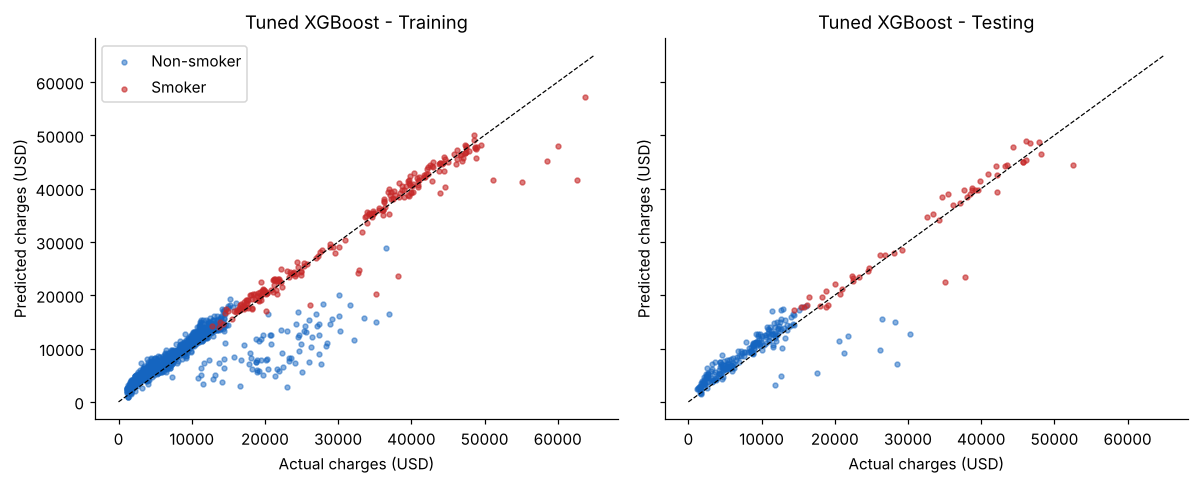

In [15]:
plot_actual_vs_pred(tuned_train_pred, tuned_test_pred, 'Tuned XGBoost', 'actual_vs_pred_tuned.png')

## **Task 16**
- *Create a line graph to compare the first 50 actual and predicted testing values using the tuned XGBoost model*

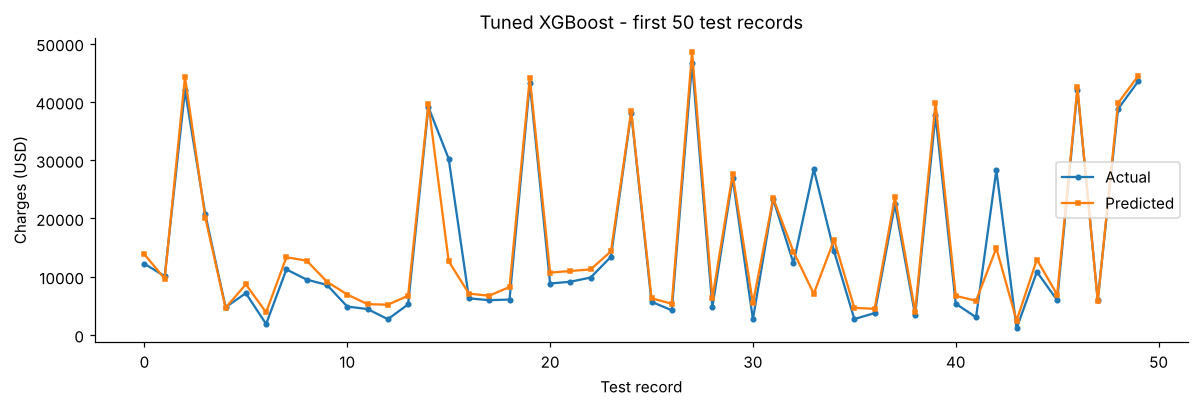

In [16]:
plot_first_50(tuned_test_pred, 'Tuned XGBoost - first 50 test records', 'first50_tuned.png')

## **Task 17**
- *Evaluate the tuned model using MSE, MAE, RMSE, MAPE, and R² score for the training and testing datasets*
- *Select an appropriate evaluation metric and calculate the gap between the training and testing scores of the tuned model to check for overfitting*

In [17]:
tuned_metrics = pd.DataFrame({'Training': regression_metrics(y_train, tuned_train_pred),
                              'Testing': regression_metrics(y_test, tuned_test_pred)})
display(tuned_metrics.round(3))
tuned_gap = tuned_metrics.loc[PRIMARY, 'Testing'] - tuned_metrics.loc[PRIMARY, 'Training']
print(f'Tuned MAE: train = {tuned_metrics.loc[PRIMARY, "Training"]:,.0f}, test = {tuned_metrics.loc[PRIMARY, "Testing"]:,.0f}, '
      f'gap (test - train) = {tuned_gap:,.0f} USD')

,Training,Testing
MSE,"16,969,781.836","12,010,526.130"
MAE,"2,313.314","2,107.723"
RMSE,"4,119.440","3,465.621"
MAPE (%),28.148,28.346
R2,0.885,0.917


Tuned MAE: train = 2,313, test = 2,108, gap (test - train) = -206 USD


**Observation:** Tuning removes the overfitting. Train MAE is USD 2,313 and test MAE USD 2,108 (the test set is slightly easier by chance). Test R² rises to 0.917 and RMSE falls from USD 4,658 to 3,466.

# Model Comparison

## **Task 18**
- *Compare the training and testing performance of the baseline and tuned XGBoost models using all regression metrics*
- *Create a DataFrame to compare the performance gaps of the baseline and tuned models using the selected evaluation metric*

In [18]:
comparison = pd.concat({'Baseline': base_metrics, 'Tuned': tuned_metrics}, axis=1).round(3)
display(comparison)
gap_df = pd.DataFrame({'Model': ['Baseline', 'Tuned'],
                       'Train MAE': [base_metrics.loc[PRIMARY, 'Training'], tuned_metrics.loc[PRIMARY, 'Training']],
                       'Test MAE': [base_metrics.loc[PRIMARY, 'Testing'], tuned_metrics.loc[PRIMARY, 'Testing']],
                       'Gap (USD)': [base_gap, tuned_gap]}).round(0)
display(gap_df)
comparison.to_csv(MET_DIR / 'baseline_vs_tuned.csv'); gap_df.to_csv(MET_DIR / 'mae_gap.csv', index=False)

Baseline                         Tuned               
            Training        Testing       Training        Testing
MSE      802,027.443 21,695,153.146 16,969,781.836 12,010,526.130
MAE          488.622      2,845.559      2,313.314      2,107.723
RMSE         895.560      4,657.806      4,119.440      3,465.621
MAPE (%)       7.266         39.145         28.148         28.346
R2             0.995          0.850          0.885          0.917

,Model,Train MAE,Test MAE,Gap (USD)
0,Baseline,489.000,"2,846.000","2,357.000"
1,Tuned,"2,313.000","2,108.000",-206.000


**Observation:** The tuned model is better on every test metric: MAE down 26% (USD 2,846 to 2,108) and R² up from 0.850 to 0.917. The baseline's excellent training scores were misleading.

# Extensions Beyond the Exercise
## A. Where do the errors come from?
Charges have a well-known structure in this dataset: smokers pay far more, and among smokers, a BMI of 30 or above (obese) roughly doubles charges again. The tuned model's test errors are split by these groups.

,n,mean_charges,MAE,median_abs_error
group,,,,
Non-smoker,213,"7,931.000","2,166.000","1,543.000"
"Smoker, BMI < 30",25,"22,233.000","2,130.000","1,036.000"
"Smoker, BMI >= 30",30,"41,050.000","1,676.000","1,199.000"


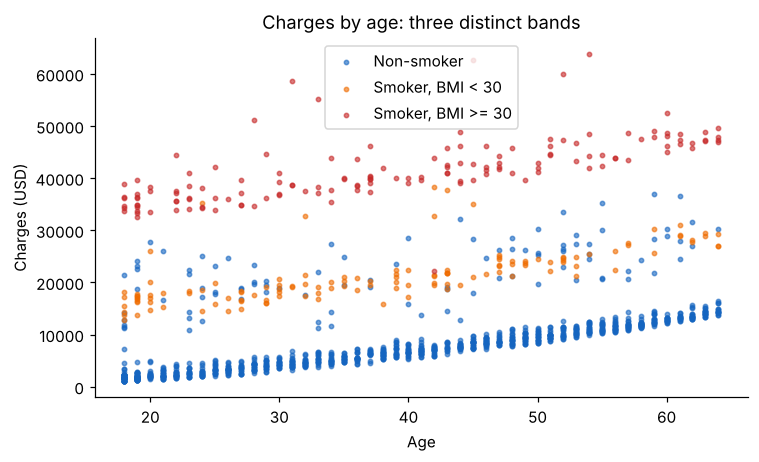

In [19]:
def risk_group(df):
    return np.where(df.smoker == 'no', 'Non-smoker', np.where(df.bmi < 30, 'Smoker, BMI < 30', 'Smoker, BMI >= 30'))

grp = risk_group(X_test)
err = pd.DataFrame({'group': grp, 'actual': y_test.values, 'pred': tuned_test_pred})
err['abs_err'] = (err.pred - err.actual).abs()
grp_tbl = err.groupby('group').agg(n=('actual', 'size'), mean_charges=('actual', 'mean'), MAE=('abs_err', 'mean'),
                                   median_abs_error=('abs_err', 'median')).round(0)
display(grp_tbl)
grp_tbl.to_csv(MET_DIR / 'error_by_risk_group.csv')

fig, ax = plt.subplots(figsize=(7, 4.3))
for g, c in zip(['Non-smoker', 'Smoker, BMI < 30', 'Smoker, BMI >= 30'], ['#1565C0', '#EF6C00', '#C62828']):
    sub = ins[risk_group(ins) == g]
    ax.scatter(sub.age, sub.charges, s=8, alpha=0.6, color=c, label=g)
ax.set_xlabel('Age'); ax.set_ylabel('Charges (USD)'); ax.set_title('Charges by age: three distinct bands'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'charges_age_bands.png', bbox_inches='tight'); plt.show()

**Observation:** Charges fall into three bands by age: non-smokers, smokers with BMI < 30, and smokers with BMI ≥ 30. The model's dollar error is **not** concentrated in the expensive smoker groups. Non-smokers have the highest MAE (USD 2,166) even though their average charge is the lowest. Some non-smokers have unexplained high charges, which no feature in the data accounts for.

## B. How much does boosting add over a transparent model?
A linear regression with two engineered terms (smoker x obese, and age squared) encodes the structure seen above explicitly. Both models are compared with repeated 5-fold CV on the full dataset.

In [20]:
def engineer(df):
    out = pd.DataFrame({'age': df.age, 'age_sq': df.age ** 2, 'bmi': df.bmi, 'children': df.children,
                        'smoker': (df.smoker == 'yes').astype(int)})
    out['smoker_x_obese'] = out.smoker * (df.bmi >= 30).astype(int)
    out['smoker_x_bmi'] = out.smoker * df.bmi
    return out

X_all_enc = pd.DataFrame(encoder.transform(X), columns=encoder.get_feature_names_out())
rows = {}
for name, model, Xm in [('Linear, raw features', LinearRegression(), X_all_enc),
                        ('Linear + smoker x BMI terms', LinearRegression(), engineer(X)),
                        ('Tuned XGBoost', XGBRegressor(**grid.best_params_, random_state=RANDOM_STATE, n_jobs=1), X_all_enc)]:
    scores = []
    for seed in range(5):
        scores.append(-cross_val_score(model, Xm, y, cv=KFold(5, shuffle=True, random_state=seed),
                                       scoring='neg_mean_absolute_error', n_jobs=-1))
    s = np.concatenate(scores)
    rows[name] = {'CV MAE (USD)': f'{s.mean():,.0f} +/- {s.std():,.0f}'}
lin_cmp = pd.DataFrame(rows).T
display(lin_cmp)
lin_cmp.to_csv(MET_DIR / 'xgboost_vs_linear_repeated_cv.csv')

lin = LinearRegression().fit(engineer(X_train), y_train)
display(pd.Series(lin.coef_, index=engineer(X_train).columns).round(1).to_frame('Coefficient (USD)'))

,CV MAE (USD)
"Linear, raw features","4,219 +/- 222"
Linear + smoker x BMI terms,"2,351 +/- 155"
Tuned XGBoost,"2,488 +/- 151"


,Coefficient (USD)
age,-55.200
age_sq,4.000
bmi,-11.000
children,776.400
smoker,384.000
smoker_x_obese,"15,048.900"
smoker_x_bmi,500.500


**Observation:** Under repeated 5-fold CV (25 fits), a **linear regression with two interaction terms** (MAE USD 2,351 ± 155) slightly outperforms the tuned XGBoost model (USD 2,488 ± 151). Without those terms, the linear model is much worse (USD 4,219). The smoker x obese coefficient alone adds about **USD 15,000** to annual charges. XGBoost finds the same structure automatically, but once that structure is written down explicitly, a fully transparent model matches it.

# Conclusion

| Model | Test MAE (USD) | Test R² |
|---|---|---|
| Baseline XGBoost (defaults) | 2,846 | 0.850 |
| Tuned XGBoost (depth 3, lr 0.05, 200 trees) | 2,108 | 0.917 |

| Repeated 5-fold CV | MAE (USD) |
|---|---|
| Linear regression, raw features | 4,219 ± 222 |
| Linear + smoker x BMI terms | 2,351 ± 155 |
| Tuned XGBoost | 2,488 ± 151 |

**Findings**
1. The default XGBoost model overfits badly on 1,069 rows. Shallow trees with a lower learning rate fix it (MAE down 26%).
2. Smoking status drives almost everything (89% of gain), and smoking combined with obesity adds about USD 15,000.
3. Once that interaction is encoded, a transparent linear model is as accurate as XGBoost. For a regulated pricing use case, that is the model I would choose.

**Limitations:** Small dataset (1,337 rows; 268 in the test set). No information on claims history or pre-existing conditions, which probably explains the large errors on some non-smokers. A single region-level geography.